# Линейная регрессия и градиентный спуск с нуля

В эксперименте линейная регрессия реализована на NumPy с помощью
среднеквадратичной ошибки (MSE) и пакетного градиентного спуска.
Синтетические данные позволяют сопоставить обученные коэффициенты
с параметрами, использованными при генерации наблюдений.

**Цели:** разобраться в градиенте MSE, исследовать кривую обучения
и сравнить результат с решением метода наименьших квадратов.

Все ошибки ниже — **MSE на обучающей выборке**. Здесь исследуется
оптимизация, а качество на новых данных не оценивается.

Выполняйте ячейки сверху вниз в окружении с NumPy и Matplotlib.

## 1. Воспроизводимые синтетические данные

Генерируем 100 наблюдений:

$$y_i = 15 + 28x_i + \epsilon_i,\qquad x_i \sim U(0, 2),\quad \epsilon_i \sim N(0, 1).$$

Seed фиксирует генерацию наблюдений и начальных коэффициентов.
Свободный член и наклон заданы явно: notebook можно выполнить
без ручного ввода.

Матрица `X_bias` добавляет к `X` столбец единиц, чтобы обучать свободный
член тем же правилом обновления, что и коэффициент при признаке.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

seed = 42
n_samples = 100
intercept = 15
slope = 28
learning_rate = 0.01
n_iterations = 400

np.random.seed(seed)
X = 2 * np.random.rand(n_samples, 1)
y = intercept + slope * X + np.random.randn(n_samples, 1)
X_bias = np.c_[np.ones(n_samples), X]

## 2. Модель, функция потерь и градиент

Вектор параметров содержит свободный член и наклон:

$$\theta = \begin{bmatrix}\theta_0 \\ \theta_1\end{bmatrix},\qquad
\hat{y} = X_{\mathrm{bias}}\theta.$$

Для $n$ наблюдений ошибка и её градиент имеют вид:

$$\operatorname{MSE}(\theta) = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2,$$

$$\nabla_\theta\operatorname{MSE} =
\frac{2}{n}X_{\mathrm{bias}}^\top(\hat{y} - y).$$

Предсказания и целевые значения имеют форму `(n_samples, 1)`.
Каждое обновление использует всю выборку — это пакетный градиентный спуск.

In [2]:
def predict(X, theta):
    return X @ theta


def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)


def gradient_mse(X, y_true, y_pred):
    return -2 / len(y_true) * (X.T @ (y_true - y_pred))

## 3. Градиентный спуск

Начинаем со случайных коэффициентов и повторяем:

$$\theta \leftarrow \theta - \eta\nabla_\theta\operatorname{MSE},\qquad \eta = 0.01.$$

Выполняем 400 обновлений. Фиксированное число шагов не
гарантирует сходимость: результат называем параметрами **после
400 обновлений**, а не оптимальными параметрами.

В `losses` записывается MSE **до** каждого обновления. Для финальных
параметров ошибка вычисляется отдельно после цикла.

In [3]:
theta = np.random.randn(X_bias.shape[1], 1)
losses = []

for iteration in range(n_iterations):
    y_pred = predict(X_bias, theta)
    losses.append(mse_loss(y, y_pred))
    gradient = gradient_mse(X_bias, y, y_pred)
    theta -= learning_rate * gradient

## 4. Финальная MSE и контрольное решение

После последнего обновления повторно вычисляем предсказания.
Теперь напечатанная MSE соответствует напечатанным параметрам.

`np.linalg.lstsq` решает ту же задачу метода наименьших квадратов
на тех же данных. Это контроль сходимости, а не замена самостоятельной
реализации градиентного спуска.

Из-за шума в наблюдениях коэффициенты контрольного решения не обязаны
точно совпадать с исходными `[15, 28]`.

In [4]:
final_predictions = predict(X_bias, theta)
final_mse = mse_loss(y, final_predictions)

theta_reference = np.linalg.lstsq(X_bias, y, rcond=None)[0]
reference_predictions = predict(X_bias, theta_reference)
reference_mse = mse_loss(y, reference_predictions)

print(f"Параметры генерации (свободный член, наклон): {[intercept, slope]}")
print(f"Параметры после {n_iterations} обновлений: {theta.ravel()}")
print(f"Финальная обучающая MSE градиентного спуска: {final_mse:.6f}")
print(f"Параметры метода наименьших квадратов: {theta_reference.ravel()}")
print(f"Обучающая MSE метода наименьших квадратов: {reference_mse:.6f}")
print(f"Разрыв обучающей MSE с контрольным решением: {final_mse - reference_mse:.6f}")

Параметры генерации (свободный член, наклон): [15, 28]
Параметры после 400 обновлений: [16.37379087 26.74704706]
Финальная обучающая MSE градиентного спуска: 1.212067
Параметры метода наименьших квадратов: [15.21509616 27.77011339]
Обучающая MSE метода наименьших квадратов: 0.806585
Разрыв обучающей MSE с контрольным решением: 0.405482


## 5. Кривая обучения и обученные прямые

Кривая включает начальную ошибку и ошибку после всех 400 обновлений.
Логарифмический масштаб MSE позволяет увидеть как раннее снижение,
так и оставшийся разрыв с контрольным решением к концу обучения.
Пунктирная линия обозначает MSE метода наименьших квадратов.

Второй график сопоставляет обученные прямые с наблюдениями.
Для прямых предсказания вычисляются на упорядоченной сетке значений `X`.

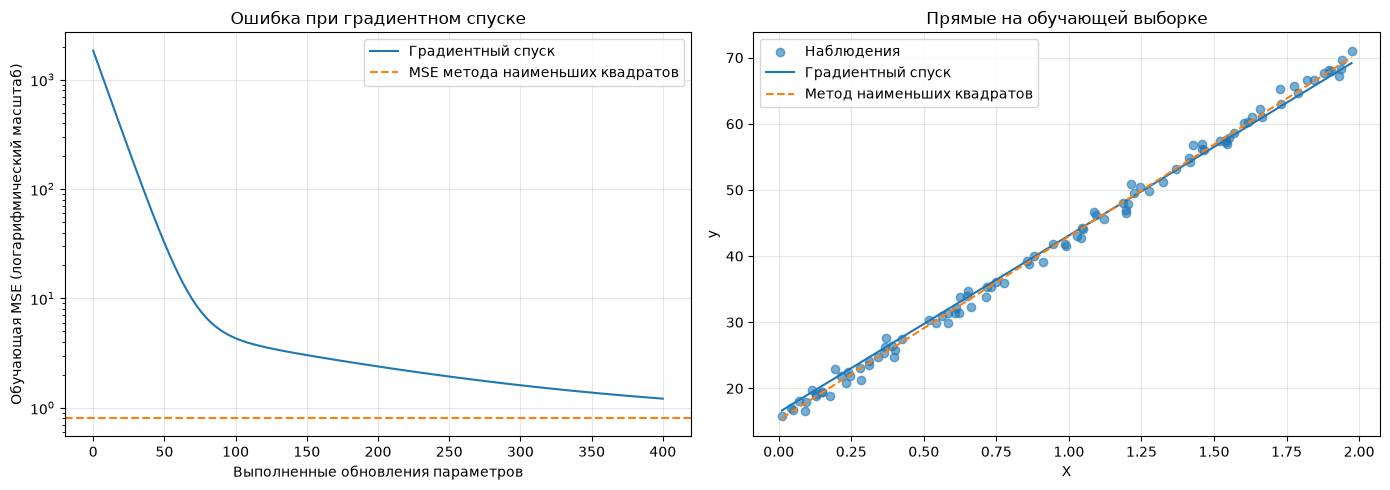

In [5]:
steps = np.arange(n_iterations + 1)
loss_history = np.append(losses, final_mse)

X_line = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
X_line_bias = np.c_[np.ones(len(X_line)), X_line]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].semilogy(steps, loss_history, label="Градиентный спуск")
axes[0].axhline(
    reference_mse, color="tab:orange", linestyle="--", label="MSE метода наименьших квадратов"
)
axes[0].set_title("Ошибка при градиентном спуске")
axes[0].set_xlabel("Выполненные обновления параметров")
axes[0].set_ylabel("Обучающая MSE (логарифмический масштаб)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X.ravel(), y.ravel(), alpha=0.6, label="Наблюдения")
axes[1].plot(
    X_line.ravel(), predict(X_line_bias, theta).ravel(), label="Градиентный спуск"
)
axes[1].plot(
    X_line.ravel(),
    predict(X_line_bias, theta_reference).ravel(),
    linestyle="--",
    label="Метод наименьших квадратов",
)
axes[1].set_title("Прямые на обучающей выборке")
axes[1].set_xlabel("X")
axes[1].set_ylabel("y")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## 6. Интерпретация и ограничения

При настройках по умолчанию MSE после 400 обновлений составляет
примерно **1.21207**, а контрольное решение достигает **0.80658**.
Разрыв показывает неполную сходимость за отведённое число шагов.
Это сравнение способов оптимизации одной модели, а не её качества
на новых данных.

Коэффициенты контрольного решения — примерно `[15.21510, 27.77011]`.
Они отличаются от `[15, 28]`, поскольку подбираются под шумные наблюдения.

Эти округлённые значения относятся к настройкам по умолчанию.
Если менять данные или параметры обучения, ориентируйтесь на заново
вычисленные метрики и графики.